# 01. Data Audit — Utility Payments A/B Test

**Цель ноутбука:** изучить исходные таблицы, проверить качество данных и связи между пользователями и попытками оплаты, зафиксировать правила подготовки данных для дальнейшего продуктового анализа.

**Исходный файл:** `dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx`

**Листы:**
- `Пользователи` — одна запись на клиента, его экспериментальная группа и характеристики;
- `Платежи` — отдельные попытки оплаты и временные метки этапов воронки.

**Ключевой принцип:** экспериментальная единица — пользователь, поскольку сплитование выполнялось по клиентам. Повторные попытки оплаты не удаляем: они нужны для дополнительного анализа, но не считаем независимыми наблюдениями в основной проверке A/B-гипотезы.


## 1. Импорт библиотек и настройки

In [ ]:
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

pd.set_option('display.max_columns', 50)
pd.set_option('display.max_rows', 100)
pd.set_option('display.float_format', lambda value: f'{value:,.3f}')

FILE_NAME = 'dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx'

CANDIDATE_PATHS = [
    Path('../data/raw') / FILE_NAME,
    Path('data/raw') / FILE_NAME,
    Path(FILE_NAME),
    Path('/mnt/data') / FILE_NAME,
]

DATA_PATH = next((path.resolve() for path in CANDIDATE_PATHS if path.exists()), None)
if DATA_PATH is None:
    checked_paths = '\n'.join(str(path.resolve()) for path in CANDIDATE_PATHS)
    raise FileNotFoundError(
        f'Не найден файл {FILE_NAME}. Проверены пути:\n{checked_paths}\n'
        'Положите Excel в data/raw/ или обновите DATA_PATH.'
    )

SHEET_USERS = 'Пользователи'
SHEET_PAYMENTS = 'Платежи'

print(f'Файл найден: {DATA_PATH}')

Файл найден: <project_root>/data/raw/dannye-dlia-keisa-po-pa-cebbefc3-5b29-4f88-b6d4-3336c88d743f.xlsx


## 2. Загрузка данных и проверка структуры

In [ ]:
users_raw = pd.read_excel(DATA_PATH, sheet_name=SHEET_USERS)
payments_raw = pd.read_excel(DATA_PATH, sheet_name=SHEET_PAYMENTS)

users = users_raw.copy()
payments = payments_raw.copy()

# Убираем случайные пробелы
users.columns = users.columns.astype(str).str.strip()
payments.columns = payments.columns.astype(str).str.strip()

required_user_columns = {'user_id', 'group', 'age', 'city', 'device_type'}
required_payment_columns = {
    'payment_id', 'user_id', 'group', 'step1_opened',
    'step2_entered', 'step3_confirmed', 'step4_success'
}

missing_user_columns = required_user_columns - set(users.columns)
missing_payment_columns = required_payment_columns - set(payments.columns)
if missing_user_columns or missing_payment_columns:
    raise ValueError(
        f'Не хватает столбцов. Пользователи: {missing_user_columns}; '
        f'Платежи: {missing_payment_columns}'
    )

print(f'Размер таблицы пользователей: {users.shape[0]:,} строк × {users.shape[1]} столбцов')
print(f'Размер таблицы платежей: {payments.shape[0]:,} строк × {payments.shape[1]} столбцов')

display(users.head())
display(payments.head())

Размер таблицы пользователей: 1,504 строк × 5 столбцов
Размер таблицы платежей: 2,661 строк × 7 столбцов


,user_id,group,age,city,device_type
0,1001,A,31,Москва,ios
1,1002,A,31,Москва,ios
2,1003,A,25,Москва,android
3,1004,A,20,Москва,ios
4,1005,A,34,Москва,ios


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
0,5001,"1,001.000",A,2024-04-16 06:06:00,2024-04-16 06:10:00,NaT,NaT
1,5002,"1,002.000",A,2024-04-12 07:38:00,2024-04-12 07:41:00,NaT,NaT
2,5003,"1,003.000",A,2024-04-26 20:03:00,2024-04-26 20:07:00,NaT,NaT
3,5004,"1,004.000",A,2024-04-09 16:02:00,NaT,NaT,NaT
4,5005,"1,004.000",A,2024-04-04 03:46:00,2024-04-04 03:54:00,2024-04-04 03:57:00,2024-04-04 04:02:00


## 3. Типы данных и общая информация

In [3]:
print('Таблица пользователей')
users.info()
print('\nТаблица платежей')
payments.info()

structure_summary = pd.DataFrame({
    'table': ['users', 'payments'],
    'rows': [len(users), len(payments)],
    'columns': [users.shape[1], payments.shape[1]],
    'unique_user_ids': [users['user_id'].nunique(dropna=True), payments['user_id'].nunique(dropna=True)],
})
display(structure_summary)

Таблица пользователей
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1504 entries, 0 to 1503
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   user_id      1504 non-null   int64 
 1   group        1503 non-null   object
 2   age          1504 non-null   int64 
 3   city         1503 non-null   object
 4   device_type  1504 non-null   object
dtypes: int64(2), object(3)
memory usage: 58.9+ KB

Таблица платежей
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2661 entries, 0 to 2660
Data columns (total 7 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   payment_id       2661 non-null   int64         
 1   user_id          2660 non-null   float64       
 2   group            2661 non-null   object        
 3   step1_opened     2661 non-null   datetime64[ns]
 4   step2_entered    2256 non-null   datetime64[ns]
 5   step3_confirmed  1719 non-null   d

,table,rows,columns,unique_user_ids
0,users,1504,5,1504
1,payments,2661,7,1501


## 4. Пропуски и дубликаты

In [4]:
def missing_summary(frame: pd.DataFrame, table_name: str) -> pd.DataFrame:
    result = pd.DataFrame({
        'table': table_name,
        'column': frame.columns,
        'missing_count': frame.isna().sum().values,
        'missing_share_pct': (frame.isna().mean().values * 100).round(2),
    })
    return result.sort_values(['missing_count', 'column'], ascending=[False, True])

missing_report = pd.concat([
    missing_summary(users, 'users'),
    missing_summary(payments, 'payments'),
], ignore_index=True)
display(missing_report)

duplicate_report = pd.DataFrame([
    {
        'table': 'users',
        'duplicate_user_id_rows': int(users['user_id'].duplicated(keep=False).sum()),
        'duplicate_key_rows': int(users.duplicated(subset=['user_id'], keep=False).sum()),
    },
    {
        'table': 'payments',
        'duplicate_payment_id_rows': int(payments['payment_id'].duplicated(keep=False).sum()),
        'duplicate_key_rows': int(payments.duplicated(subset=['payment_id'], keep=False).sum()),
    },
])
display(duplicate_report)

# Отдельно выводим строки с пропущенными ключами — их нельзя корректно связать между таблицами.
display(users.loc[users['user_id'].isna() | users['group'].isna()])
display(payments.loc[payments['payment_id'].isna() | payments['user_id'].isna()])

,table,column,missing_count,missing_share_pct
0,users,city,1,0.070
1,users,group,1,0.070
2,users,age,0,0.000
3,users,device_type,0,0.000
4,users,user_id,0,0.000
5,payments,step4_success,1139,42.800
6,payments,step3_confirmed,942,35.400
7,payments,step2_entered,405,15.220
8,payments,user_id,1,0.040
9,payments,group,0,0.000


,table,duplicate_user_id_rows,duplicate_key_rows,duplicate_payment_id_rows
0,users,0.000,0,NaN
1,payments,NaN,0,0.000


,user_id,group,age,city,device_type
1500,9001,NaN,25,Москва,ios


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


## 5. Проверка категориальных полей и аномальных значений

In [ ]:
# Нормализуем только формат категориальных значений
for column in ['group', 'city', 'device_type']:
    users[column] = users[column].map(lambda value: value.strip() if isinstance(value, str) else value)
for column in ['group']:
    users[column] = users[column].map(lambda value: value.upper() if isinstance(value, str) else value)
    payments[column] = payments[column].map(lambda value: value.strip().upper() if isinstance(value, str) else value)
users['device_type'] = users['device_type'].map(
    lambda value: value.lower() if isinstance(value, str) else value
)

for column in ['group', 'city', 'device_type']:
    print(f'Распределение {column}:')
    display(users[column].value_counts(dropna=False).rename_axis(column).to_frame('users'))

# Ожидаемые категории задаём явно
invalid_group_users = users.loc[users['group'].notna() & ~users['group'].isin(['A', 'B'])]
invalid_group_payments = payments.loc[payments['group'].notna() & ~payments['group'].isin(['A', 'B'])]

users['age_numeric'] = pd.to_numeric(users['age'], errors='coerce')
invalid_age_mask = users['age_numeric'].notna() & ~users['age_numeric'].between(0, 100)
invalid_age_users = users.loc[invalid_age_mask, ['user_id', 'group', 'age', 'city', 'device_type']]

print('Неожиданные значения группы в users:', len(invalid_group_users))
print('Неожиданные значения группы в payments:', len(invalid_group_payments))
print('Некорректный возраст (вне диапазона 0–100):', len(invalid_age_users))
display(invalid_age_users)

Распределение group:


,users
group,
A,752
B,751
NaN,1


Распределение city:


,users
city,
Москва,595
Регион,514
СПб,394
NaN,1


Распределение device_type:


,users
device_type,
android,777
ios,727


Неожиданные значения группы в users: 0
Неожиданные значения группы в payments: 0
Некорректный возраст (вне диапазона 0–100): 2


,user_id,group,age,city,device_type
1501,9002,A,-5,СПб,android
1502,9003,B,150,Регион,ios


## 6. Проверка связей между таблицами

In [ ]:
users_with_id = users.loc[users['user_id'].notna()].copy()
payments_with_id = payments.loc[payments['user_id'].notna()].copy()

user_ids = set(users_with_id['user_id'])
payment_user_ids = set(payments_with_id['user_id'])

unmatched_payments = payments.loc[
    payments['user_id'].notna() & ~payments['user_id'].isin(user_ids)
].copy()
users_without_payments = users_with_id.loc[
    ~users_with_id['user_id'].isin(payment_user_ids)
].copy()

# Проверяем расхождение группы между таблицами
payment_group_check = payments_with_id.merge(
    users_with_id[['user_id', 'group']].rename(columns={'group': 'user_group'}),
    on='user_id',
    how='left',
    validate='many_to_one'
)
group_mismatch = payment_group_check.loc[
    payment_group_check['group'].notna()
    & payment_group_check['user_group'].notna()
    & (payment_group_check['group'] != payment_group_check['user_group'])
].copy()

linkage_summary = pd.DataFrame([
    {'check': 'Платежи без user_id', 'rows': int(payments['user_id'].isna().sum())},
    {'check': 'Платежи с user_id, которого нет в users', 'rows': len(unmatched_payments)},
    {'check': 'Пользователи без попыток оплаты', 'rows': len(users_without_payments)},
    {'check': 'Платежи с конфликтом группы', 'rows': len(group_mismatch)},
])
display(linkage_summary)

print('Платежи без user_id:')
display(payments.loc[payments['user_id'].isna()])
print('Пользователи без попыток оплаты:')
display(users_without_payments)
print('Конфликты экспериментальной группы:')
display(group_mismatch[['payment_id', 'user_id', 'group', 'user_group']])

,check,rows
0,Платежи без user_id,1
1,"Платежи с user_id, которого нет в users",0
2,Пользователи без попыток оплаты,3
3,Платежи с конфликтом группы,1


Платежи без user_id:


,payment_id,user_id,group,step1_opened,step2_entered,step3_confirmed,step4_success
2660,99003,NaN,A,2024-04-12 09:15:00,NaT,NaT,NaT


Пользователи без попыток оплаты:


,user_id,group,age,city,device_type,age_numeric
1500,9001,NaN,25,Москва,ios,25
1501,9002,A,-5,СПб,android,-5
1502,9003,B,150,Регион,ios,150


Конфликты экспериментальной группы:


,payment_id,user_id,group,user_group
2659,99002,"1,010.000",B,A


## 7. Повторные попытки оплаты

In [7]:
attempts_per_user = (
    payments_with_id
    .groupby('user_id')['payment_id']
    .nunique()
    .rename('attempts')
)

attempt_distribution = (
    attempts_per_user
    .value_counts()
    .sort_index()
    .rename_axis('attempts_per_user')
    .reset_index(name='users')
)

display(attempt_distribution)

print(f'Всего попыток с известным user_id: {len(payments_with_id):,}')
print(f'Уникальных пользователей с попытками: {payments_with_id["user_id"].nunique():,}')
print(f'Пользователей без попыток: {len(users_without_payments):,}')
print(f'Максимальное количество попыток на пользователя: {attempts_per_user.max()}')

,attempts_per_user,users
0,1,740
1,2,443
2,3,238
3,4,80


Всего попыток с известным user_id: 2,660
Уникальных пользователей с попытками: 1,501
Пользователей без попыток: 3
Максимальное количество попыток на пользователя: 4


Повторные попытки сохраняются. Для основной пользовательской метрики каждый клиент будет учитываться один раз. Отдельный анализ на уровне попыток возможен, но в статистических выводах нужно учитывать кластеризацию попыток внутри одного пользователя.

## 8. Проверка временных меток этапов воронки

In [ ]:
stage_columns = [
    'step1_opened',
    'step2_entered',
    'step3_confirmed',
    'step4_success',
]

def parse_excel_datetime(series: pd.Series) -> pd.Series:
    """Преобразует Excel serial date или уже распознанные даты в datetime."""
    if pd.api.types.is_datetime64_any_dtype(series):
        return pd.to_datetime(series, errors='coerce')

    numeric = pd.to_numeric(series, errors='coerce')
    result = pd.Series(pd.NaT, index=series.index, dtype='datetime64[ns]')
    numeric_mask = numeric.notna()

    # В исходном файле значения похожи на Excel serial dates (число дней от 1899-12-30).
    if numeric_mask.any():
        result.loc[numeric_mask] = pd.to_datetime(
            numeric.loc[numeric_mask], unit='D', origin='1899-12-30', errors='coerce'
        )

    text_mask = ~numeric_mask & series.notna()
    if text_mask.any():
        result.loc[text_mask] = pd.to_datetime(series.loc[text_mask], errors='coerce')

    return result

for column in stage_columns:
    payments[column] = parse_excel_datetime(payments[column])

print('Пропуски по этапам:')
display(payments[stage_columns].isna().sum().rename('missing_count').to_frame())

sequence_issues = []
for previous_step, current_step in zip(stage_columns[:-1], stage_columns[1:]):
    missing_previous = payments[current_step].notna() & payments[previous_step].isna()
    time_reversal = (
        payments[current_step].notna()
        & payments[previous_step].notna()
        & (payments[current_step] < payments[previous_step])
    )
    sequence_issues.append({
        'transition': f'{previous_step} -> {current_step}',
        'later_step_without_previous': int(missing_previous.sum()),
        'timestamp_order_violations': int(time_reversal.sum()),
    })
sequence_report = pd.DataFrame(sequence_issues)
display(sequence_report)

all_timestamps = payments[stage_columns].stack().dropna()
print('Минимальная временная метка:', all_timestamps.min())
print('Максимальная временная метка:', all_timestamps.max())

period_start = pd.Timestamp('2024-04-01 00:00:00')
period_end = pd.Timestamp('2024-05-01 00:00:00')  # правая граница не включается
outside_test_period = (all_timestamps < period_start) | (all_timestamps >= period_end)
print('Количество временных меток вне периода эксперимента:', int(outside_test_period.sum()))

Пропуски по этапам:


,missing_count
step1_opened,0
step2_entered,405
step3_confirmed,942
step4_success,1139


,transition,later_step_without_previous,timestamp_order_violations
0,step1_opened -> step2_entered,0,0
1,step2_entered -> step3_confirmed,0,0
2,step3_confirmed -> step4_success,0,0


Минимальная временная метка: 2024-04-01 00:19:00
Максимальная временная метка: 2024-04-30 23:30:00
Количество временных меток вне периода эксперимента: 0


## 9. Проверка распределения пользователей по группам (SRM check)

In [ ]:
known_group_users = users.loc[users['group'].isin(['A', 'B']) & users['user_id'].notna()].copy()
group_sizes = known_group_users.groupby('group')['user_id'].nunique()
group_sizes = group_sizes.reindex(['A', 'B'], fill_value=0)

split_summary = pd.DataFrame({
    'users': group_sizes,
    'share_pct': (group_sizes / group_sizes.sum() * 100).round(2),
})
display(split_summary)

print(f'Пользователей с известной группой: {int(group_sizes.sum()):,}')
print(f'Пользователей без группы: {int(users["group"].isna().sum()):,}')

EXPECTED_B_SHARE = 0.5
try:
    from scipy.stats import binomtest
    n_total = int(group_sizes.sum())
    n_b = int(group_sizes.loc['B'])
    srm_test = binomtest(n_b, n=n_total, p=EXPECTED_B_SHARE, alternative='two-sided')
    print(f'SRM binomial test при ожидаемом B share = {EXPECTED_B_SHARE:.0%}: p-value = {srm_test.pvalue:.4f}')
except ImportError:
    print('Для точной биномиальной проверки установите scipy: pip install scipy')

,users,share_pct
group,,
A,752,50.030
B,751,49.970


Пользователей с известной группой: 1,503
Пользователей без группы: 1


SRM binomial test при ожидаемом B share = 50%: p-value = 1.0000


## 10. Визуальный первичный анализ (EDA)

В этом разделе строим графики, которые помогают понять состав аудитории, структуру попыток оплаты и временные характеристики процесса.


In [ ]:

known_group_users = users.loc[
    users['user_id'].notna() & users['group'].isin(['A', 'B'])
].copy()

# Справочник назначенных групп
user_group_map = known_group_users[['user_id', 'group']].drop_duplicates('user_id')

payments_for_eda = payments.loc[payments['user_id'].notna()].merge(
    user_group_map,
    on='user_id',
    how='inner',
    suffixes=('_payment', '_assigned'),
    validate='many_to_one'
)
payments_for_eda = payments_for_eda.rename(columns={'group_assigned': 'assigned_group'})

# Пользовательская таблица с числом попыток
attempts_count = (
    payments_for_eda.groupby('user_id')['payment_id']
    .nunique()
    .rename('attempts_count')
)
users_for_eda = known_group_users.merge(
    attempts_count,
    on='user_id',
    how='left',
    validate='one_to_one'
)
users_for_eda['attempts_count'] = users_for_eda['attempts_count'].fillna(0).astype(int)

# Валидный возраст используем только в графиках возрастного распределения.
users_for_eda['age_numeric'] = pd.to_numeric(users_for_eda['age'], errors='coerce')
users_for_eda['age_valid'] = users_for_eda['age_numeric'].where(
    users_for_eda['age_numeric'].between(0, 100)
)

plt.rcParams.update({
    'figure.figsize': (9, 5),
    'axes.titlesize': 13,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
    'figure.dpi': 110,
})

print(f'Пользователей с известной группой: {len(users_for_eda):,}')
print(f'Попыток, связанных с пользователем и известной группой: {len(payments_for_eda):,}')
print(f'Попыток с конфликтом исходной и назначенной группы: '
      f'{int((payments_for_eda["group_payment"] != payments_for_eda["assigned_group"]).sum())}')

Пользователей с известной группой: 1,503
Попыток, связанных с пользователем и известной группой: 2,660
Попыток с конфликтом исходной и назначенной группы: 1


### 10.1. Размер экспериментальных групп

Показываем количество пользователей по назначенной группе. Пользователь без группы выделен отдельно: он не может участвовать в сравнении A/B, но должен остаться в аудите качества данных.

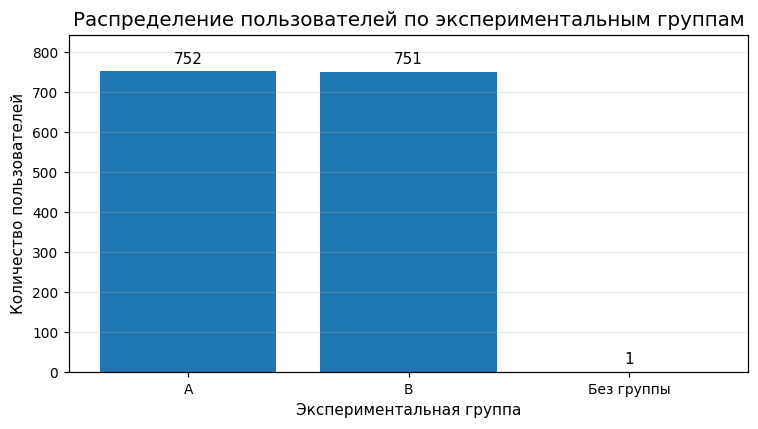

Доли среди пользователей с известной группой:


,share_pct
group,
A,50.030
B,49.970


In [11]:
group_counts_all = users['group'].value_counts(dropna=False).reindex(['A', 'B'])
unknown_group_count = int(users['group'].isna().sum())
labels = ['A', 'B'] + (['Без группы'] if unknown_group_count else [])
values = [int(group_counts_all.get('A', 0)), int(group_counts_all.get('B', 0))]
if unknown_group_count:
    values.append(unknown_group_count)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(labels, values)
ax.set_title('Распределение пользователей по экспериментальным группам')
ax.set_xlabel('Экспериментальная группа')
ax.set_ylabel('Количество пользователей')
ax.bar_label(bars, padding=3, fmt='%d')
ax.set_ylim(0, max(values) * 1.12)
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

print('Доли среди пользователей с известной группой:')
display((known_group_users['group'].value_counts(normalize=True)
         .reindex(['A', 'B']).mul(100).round(2)
         .rename('share_pct').to_frame()))

### 10.2. География и тип устройства


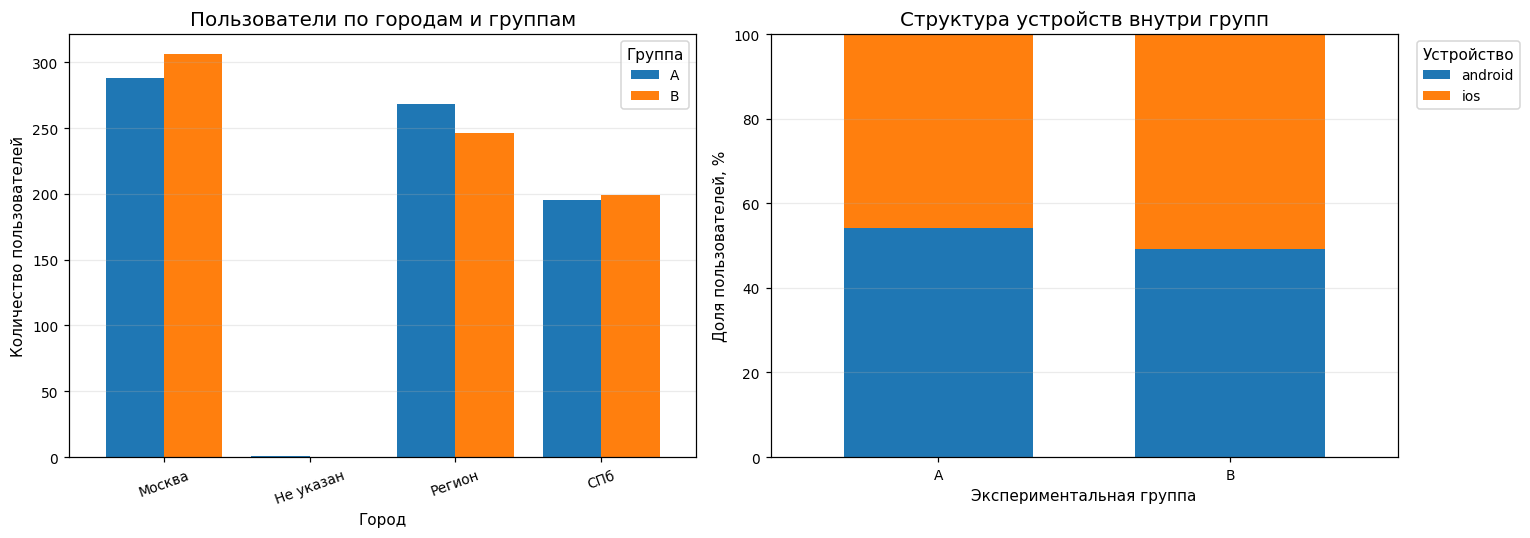

device_type,android,ios,All
group,,,
A,408,344,752
B,369,382,751
All,777,726,1503


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Города
city_data = users_for_eda.assign(city_plot=users_for_eda['city'].fillna('Не указан'))
city_table = pd.crosstab(city_data['city_plot'], city_data['group']).reindex(columns=['A', 'B'], fill_value=0)
city_table.plot(kind='bar', ax=axes[0], width=0.8)
axes[0].set_title('Пользователи по городам и группам')
axes[0].set_xlabel('Город')
axes[0].set_ylabel('Количество пользователей')
axes[0].tick_params(axis='x', rotation=20)
axes[0].legend(title='Группа')
axes[0].grid(axis='y', alpha=0.25)

# Тип устройства
device_table = pd.crosstab(users_for_eda['group'], users_for_eda['device_type'], normalize='index') * 100
device_table = device_table.reindex(['A', 'B'])
device_table.plot(kind='bar', stacked=True, ax=axes[1], width=0.65)
axes[1].set_title('Структура устройств внутри групп')
axes[1].set_xlabel('Экспериментальная группа')
axes[1].set_ylabel('Доля пользователей, %')
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Устройство', bbox_to_anchor=(1.02, 1), loc='upper left')
axes[1].grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

display(pd.crosstab(users_for_eda['group'], users_for_eda['device_type'], margins=True))

### 10.3. Распределение возраста

Для графика исключаем только некорректные значения возраста (меньше 0 или больше 100).

/tmp/ipykernel_1301/4236113928.py:16: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(age_values, labels=['A', 'B'], showmeans=True)


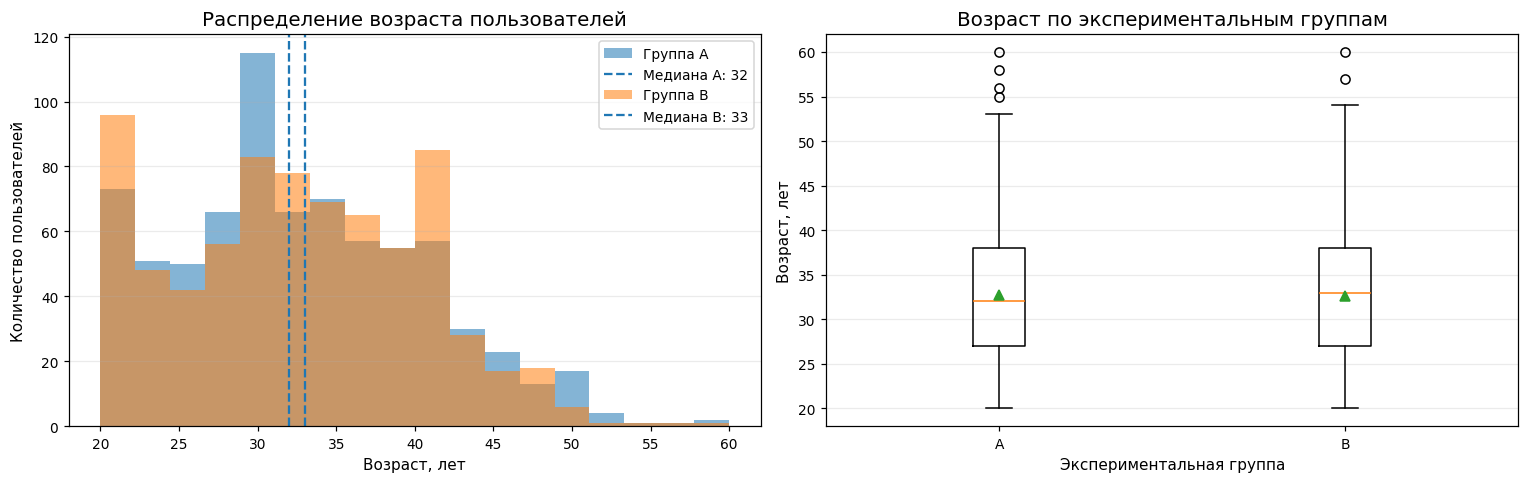

В возрастных графиках использовано 1,501 пользователей; некорректных возрастов исключено только из этого среза: 2.


In [13]:
age_data = users_for_eda.dropna(subset=['age_valid']).copy()
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

for group in ['A', 'B']:
    group_ages = age_data.loc[age_data['group'] == group, 'age_valid']
    axes[0].hist(group_ages, bins=18, alpha=0.55, label=f'Группа {group}')
    axes[0].axvline(group_ages.median(), linestyle='--', linewidth=1.5,
                    label=f'Медиана {group}: {group_ages.median():.0f}')
axes[0].set_title('Распределение возраста пользователей')
axes[0].set_xlabel('Возраст, лет')
axes[0].set_ylabel('Количество пользователей')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.25)

age_values = [age_data.loc[age_data['group'] == group, 'age_valid'].dropna() for group in ['A', 'B']]
axes[1].boxplot(age_values, labels=['A', 'B'], showmeans=True)
axes[1].set_title('Возраст по экспериментальным группам')
axes[1].set_xlabel('Экспериментальная группа')
axes[1].set_ylabel('Возраст, лет')
axes[1].grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()
print(f'В возрастных графиках использовано {len(age_data):,} пользователей; '
      f'некорректных возрастов исключено только из этого среза: {len(users_for_eda) - len(age_data)}.')

### 10.4. Профиль проблем качества данных

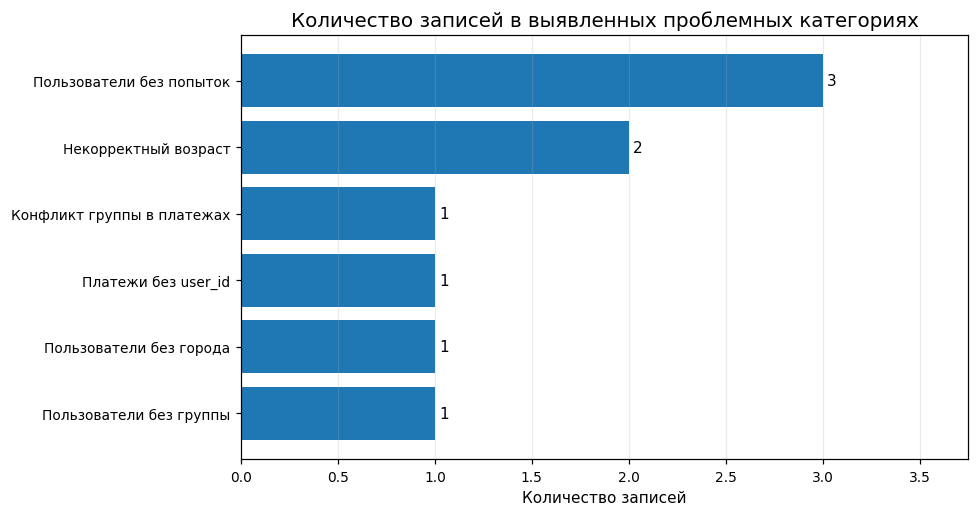

In [14]:
quality_counts = pd.Series({
    'Пользователи без группы': int(users['group'].isna().sum()),
    'Пользователи без города': int(users['city'].isna().sum()),
    'Некорректный возраст': int(invalid_age_mask.sum()),
    'Платежи без user_id': int(payments['user_id'].isna().sum()),
    'Конфликт группы в платежах': int(len(group_mismatch)),
    'Пользователи без попыток': int(len(users_without_payments)),
}).sort_values()

fig, ax = plt.subplots(figsize=(9, 4.8))
bars = ax.barh(quality_counts.index, quality_counts.values)
ax.set_title('Количество записей в выявленных проблемных категориях')
ax.set_xlabel('Количество записей')
ax.bar_label(bars, padding=3, fmt='%d')
ax.set_xlim(0, max(quality_counts.max(), 1) * 1.25)
ax.grid(axis='x', alpha=0.25)
plt.tight_layout()
plt.show()

### 10.5. Повторные попытки оплаты

Считаем количество попыток на пользователя. Это важная характеристика поведения: анализ только строк платежей не показывает пользователей, которые были назначены в эксперимент, но не начали оплату.

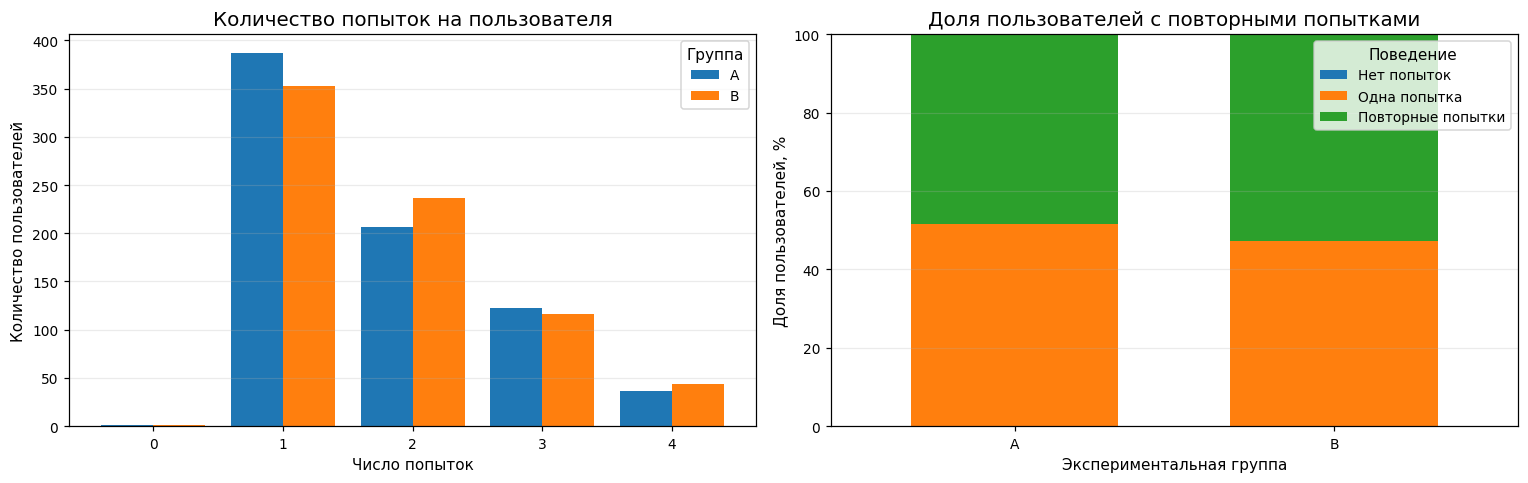

attempts_count,0,1,2,3,4
group,,,,,
A,1,387,206,122,36
B,1,353,237,116,44


In [ ]:
attempt_dist = (users_for_eda.groupby(['group', 'attempts_count'])['user_id']
                .nunique().unstack(fill_value=0).reindex(index=['A', 'B'], fill_value=0))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
attempt_dist.T.plot(kind='bar', ax=axes[0], width=0.8)
axes[0].set_title('Количество попыток на пользователя')
axes[0].set_xlabel('Число попыток')
axes[0].set_xticks(range(int(users_for_eda['attempts_count'].max()) + 1))
axes[0].set_ylabel('Количество пользователей')
axes[0].tick_params(axis='x', rotation=0)
axes[0].legend(title='Группа')
axes[0].grid(axis='y', alpha=0.25)

# Выделяем три непересекающиеся категории
users_for_eda['attempt_category'] = np.select(
    [users_for_eda['attempts_count'].eq(0), users_for_eda['attempts_count'].eq(1)],
    ['Нет попыток', 'Одна попытка'],
    default='Повторные попытки'
)
repeat_share = (pd.crosstab(users_for_eda['group'], users_for_eda['attempt_category'], normalize='index') * 100)
repeat_share = repeat_share.reindex(
    index=['A', 'B'],
    columns=['Нет попыток', 'Одна попытка', 'Повторные попытки'],
    fill_value=0
)
repeat_share.plot(kind='bar', stacked=True, ax=axes[1], width=0.65)
axes[1].set_title('Доля пользователей с повторными попытками')
axes[1].set_xlabel('Экспериментальная группа')
axes[1].set_ylabel('Доля пользователей, %')
axes[1].set_ylim(0, 100)
axes[1].tick_params(axis='x', rotation=0)
axes[1].legend(title='Поведение')
axes[1].grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

display(attempt_dist.rename_axis(columns='attempts_count'))

### 10.6. Этапы воронки на уровне платежных попыток

Для каждой попытки проверяем, зафиксирована ли временная метка соответствующего этапа.

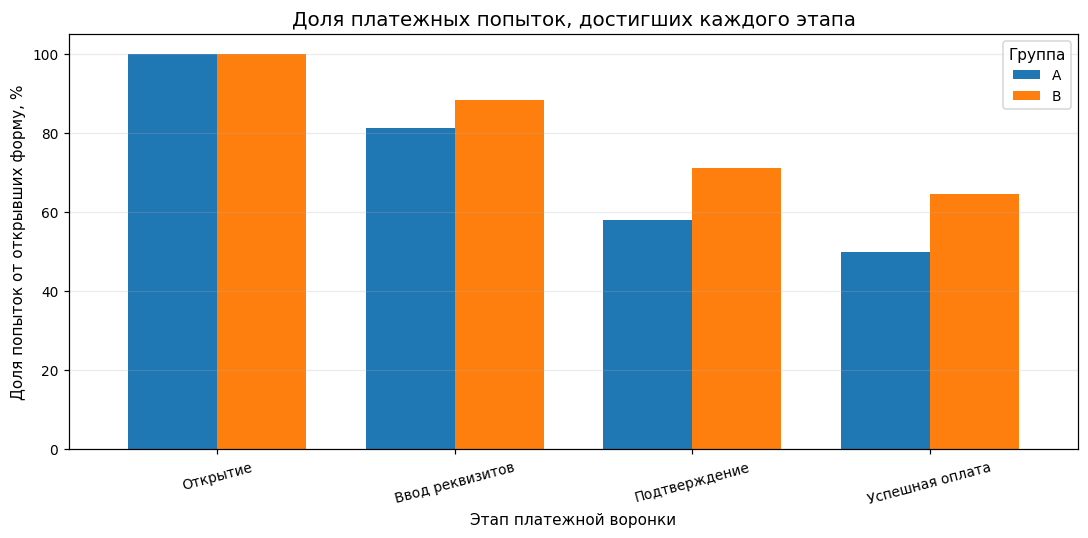

,Открытие,Ввод реквизитов,Подтверждение,Успешная оплата
assigned_group,,,,
A,100.000,81.130,57.980,49.810
B,100.000,88.380,71.060,64.400


In [16]:
stage_labels = {
    'step1_opened': 'Открытие',
    'step2_entered': 'Ввод реквизитов',
    'step3_confirmed': 'Подтверждение',
    'step4_success': 'Успешная оплата',
}
stage_order = list(stage_labels.keys())

attempt_funnel = payments_for_eda.groupby('assigned_group')[stage_order].apply(
    lambda frame: frame.notna().mean() * 100
).reindex(['A', 'B'])
attempt_funnel = attempt_funnel.rename(columns=stage_labels)

ax = attempt_funnel.T.plot(kind='bar', figsize=(10, 5), width=0.75)
ax.set_title('Доля платежных попыток, достигших каждого этапа')
ax.set_xlabel('Этап платежной воронки')
ax.set_ylabel('Доля попыток от открывших форму, %')
ax.set_ylim(0, 105)
ax.tick_params(axis='x', rotation=15)
ax.legend(title='Группа')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()
display(attempt_funnel.round(2))

### 10.7. Достижение этапов на уровне уникальных пользователей

Для каждого клиента отмечаем, достигал ли он этапа хотя бы в одной попытке.

/tmp/ipykernel_1301/3996632748.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  user_funnel[column] = user_funnel[column].fillna(False).astype(bool)
/tmp/ipykernel_1301/3996632748.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  user_funnel[column] = user_funnel[column].fillna(False).astype(bool)
/tmp/ipykernel_1301/3996632748.py:9: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_o

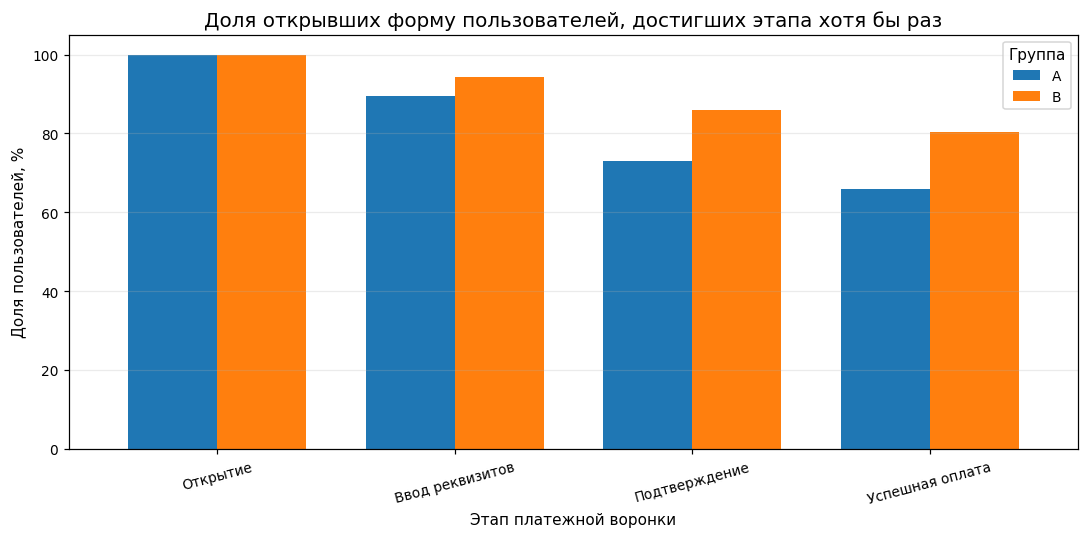

,Открытие,Ввод реквизитов,Подтверждение,Успешная оплата
group,,,,
A,100.000,89.480,73.100,65.780
B,100.000,94.270,85.870,80.400


In [17]:
user_stage_flags = payments_for_eda.groupby('user_id')[stage_order].agg(lambda s: s.notna().any())
user_funnel = users_for_eda[['user_id', 'group']].merge(
    user_stage_flags,
    on='user_id',
    how='left',
    validate='one_to_one'
)
for column in stage_order:
    user_funnel[column] = user_funnel[column].fillna(False).astype(bool)

opened_users = user_funnel.loc[user_funnel['step1_opened']].copy()
user_funnel_rates = opened_users.groupby('group')[stage_order].mean().mul(100).reindex(['A', 'B'])
user_funnel_rates = user_funnel_rates.rename(columns=stage_labels)

ax = user_funnel_rates.T.plot(kind='bar', figsize=(10, 5), width=0.75)
ax.set_title('Доля открывших форму пользователей, достигших этапа хотя бы раз')
ax.set_xlabel('Этап платежной воронки')
ax.set_ylabel('Доля пользователей, %')
ax.set_ylim(0, 105)
ax.tick_params(axis='x', rotation=15)
ax.legend(title='Группа')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()
display(user_funnel_rates.round(2))

### 10.8. Динамика попыток в течение эксперимента

Показываем количество начатых и успешно завершённых платежных попыток по дням.

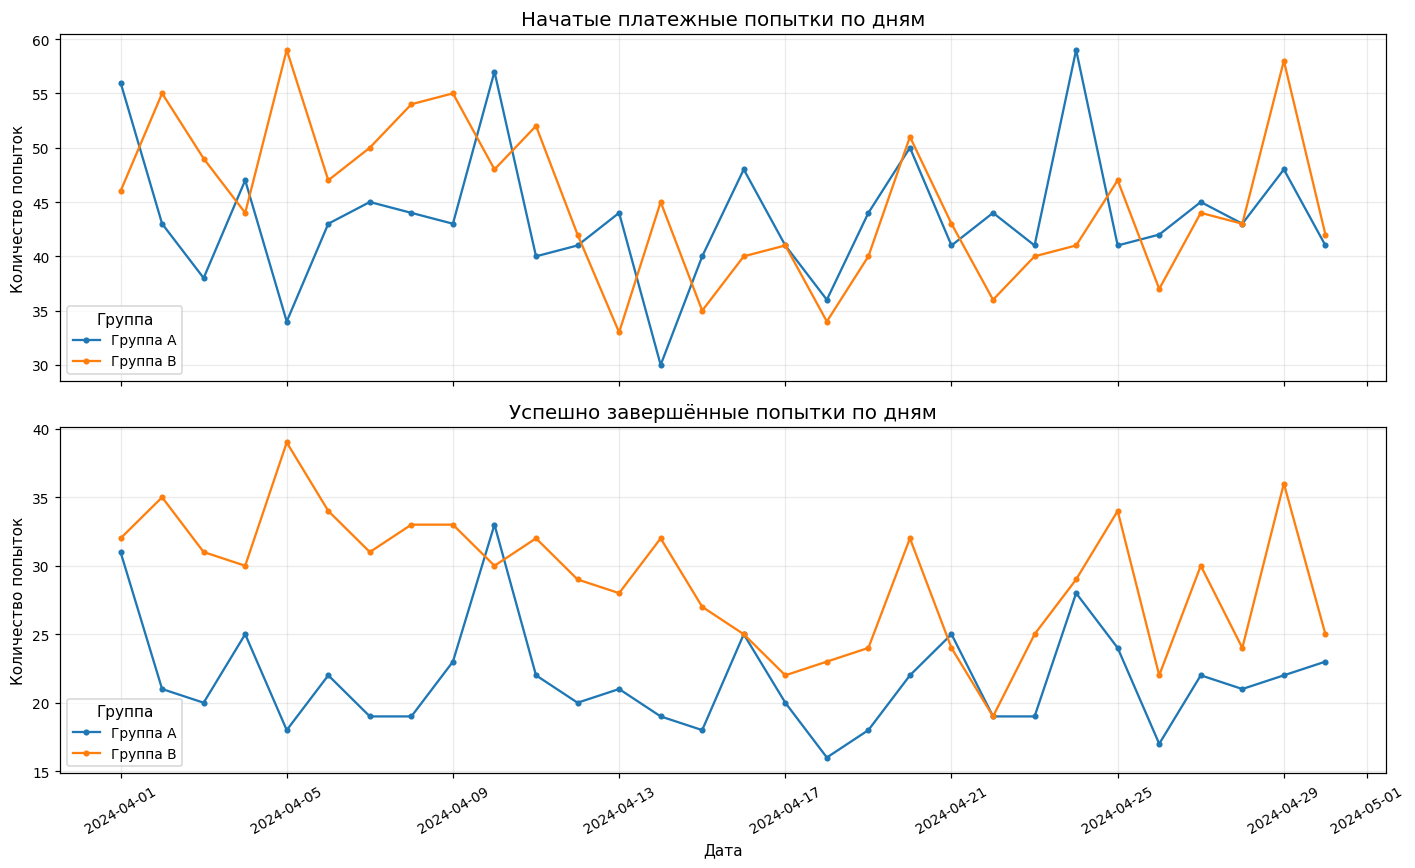

In [18]:
daily_open = payments_for_eda.assign(date=payments_for_eda['step1_opened'].dt.floor('D'))
daily_success = payments_for_eda.loc[payments_for_eda['step4_success'].notna()].copy()
daily_success['date'] = daily_success['step4_success'].dt.floor('D')
all_days = pd.date_range('2024-04-01', '2024-04-30', freq='D')

fig, axes = plt.subplots(2, 1, figsize=(13, 8), sharex=True)
for group in ['A', 'B']:
    opened_series = (daily_open.loc[daily_open['assigned_group'] == group]
                     .groupby('date')['payment_id'].nunique().reindex(all_days, fill_value=0))
    success_series = (daily_success.loc[daily_success['assigned_group'] == group]
                      .groupby('date')['payment_id'].nunique().reindex(all_days, fill_value=0))
    axes[0].plot(all_days, opened_series.values, marker='o', markersize=3, label=f'Группа {group}')
    axes[1].plot(all_days, success_series.values, marker='o', markersize=3, label=f'Группа {group}')

axes[0].set_title('Начатые платежные попытки по дням')
axes[0].set_ylabel('Количество попыток')
axes[1].set_title('Успешно завершённые попытки по дням')
axes[1].set_ylabel('Количество попыток')
axes[1].set_xlabel('Дата')
for ax in axes:
    ax.legend(title='Группа')
    ax.grid(alpha=0.25)
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

### 10.9. Время между этапами платежа

Рассчитываем продолжительность между соседними этапами в минутах только для попыток, у которых заполнены обе временные метки.

/tmp/ipykernel_1301/1545153996.py:28: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  ax.boxplot(box_data, labels=box_labels, showfliers=True, showmeans=True)


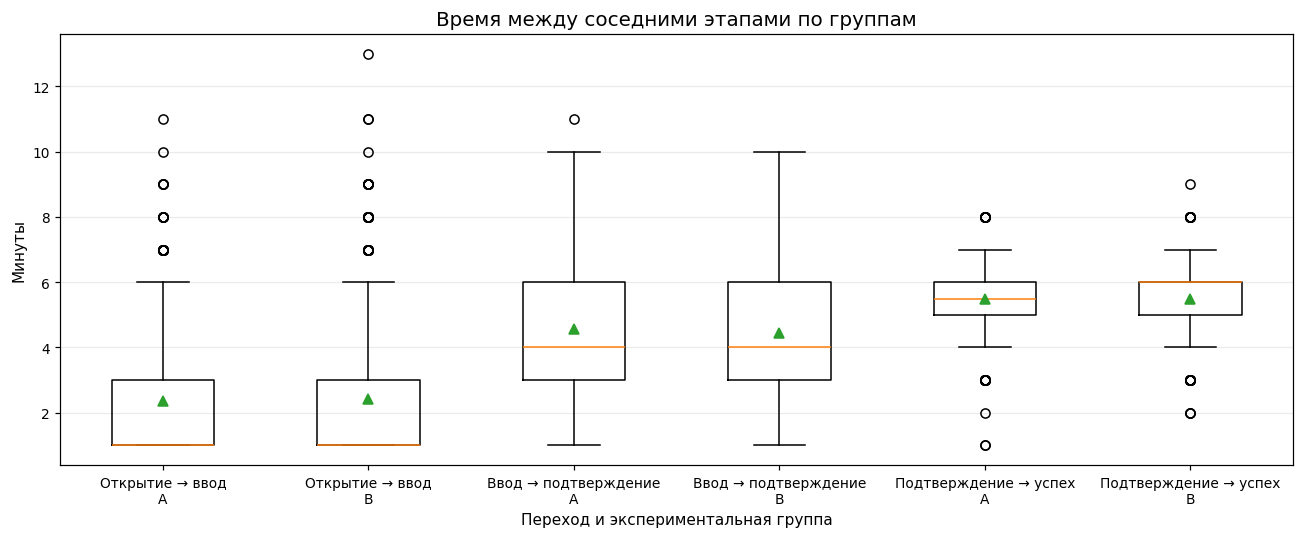

count  median  mean   std
transition            assigned_group                           
Ввод → подтверждение  A                 759   4.000 4.550 1.840
                      B                 960   4.000 4.430 1.990
Открытие → ввод       A                1062   1.000 2.350 1.800
                      B                1194   1.000 2.430 1.920
Подтверждение → успех A                 652   5.500 5.480 1.100
                      B                 870   6.000 5.480 1.030

In [19]:
transition_definitions = [
    ('step1_opened', 'step2_entered', 'Открытие → ввод'),
    ('step2_entered', 'step3_confirmed', 'Ввод → подтверждение'),
    ('step3_confirmed', 'step4_success', 'Подтверждение → успех'),
]

duration_records = []
for start_col, end_col, label in transition_definitions:
    mask = payments_for_eda[start_col].notna() & payments_for_eda[end_col].notna()
    subset = payments_for_eda.loc[mask, ['assigned_group', start_col, end_col]].copy()
    subset['duration_minutes'] = (subset[end_col] - subset[start_col]).dt.total_seconds() / 60
    subset['transition'] = label
    duration_records.append(subset[['assigned_group', 'transition', 'duration_minutes']])

durations = pd.concat(duration_records, ignore_index=True)
fig, ax = plt.subplots(figsize=(12, 5))
box_data, box_labels = [], []
for transition in [item[2] for item in transition_definitions]:
    for group in ['A', 'B']:
        values = durations.loc[
            (durations['transition'] == transition)
            & (durations['assigned_group'] == group),
            'duration_minutes'
        ].dropna()
        box_data.append(values)
        box_labels.append('{}\n{}'.format(transition, group))

ax.boxplot(box_data, labels=box_labels, showfliers=True, showmeans=True)
ax.set_title('Время между соседними этапами по группам')
ax.set_ylabel('Минуты')
ax.set_xlabel('Переход и экспериментальная группа')
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

display(durations.groupby(['transition', 'assigned_group'])['duration_minutes']
        .agg(['count', 'median', 'mean', 'std']).round(2))

### 10.10. В какое время пользователи начинают оплату

Распределение открытий формы по часу суток — дополнительный контекст для планирования коммуникаций и интерпретации временной динамики.

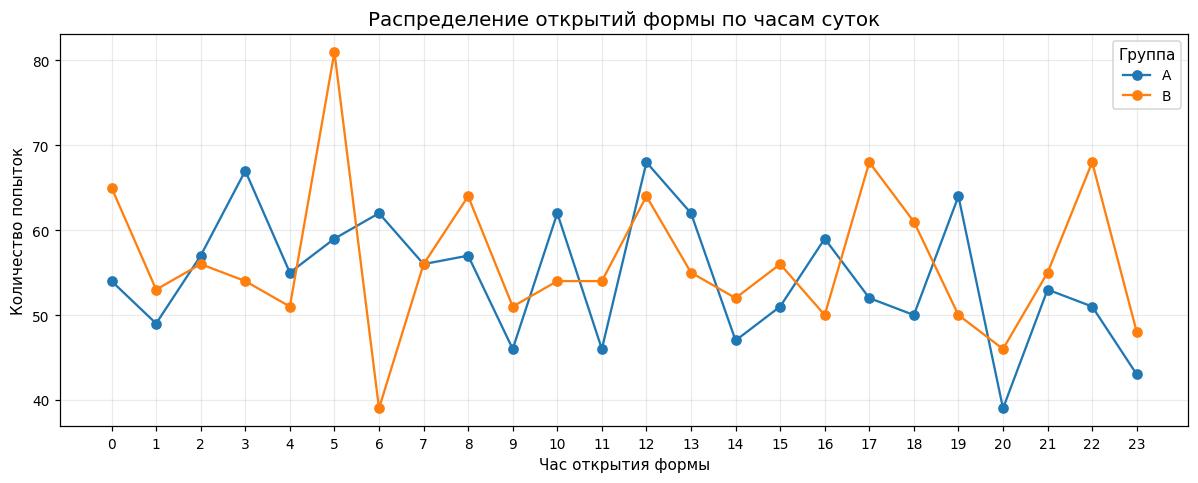

In [20]:
hourly = (payments_for_eda.assign(hour=payments_for_eda['step1_opened'].dt.hour)
          .groupby(['hour', 'assigned_group'])['payment_id']
          .nunique().unstack(fill_value=0).reindex(range(24), fill_value=0))

ax = hourly.plot(kind='line', marker='o', figsize=(11, 4.5))
ax.set_title('Распределение открытий формы по часам суток')
ax.set_xlabel('Час открытия формы')
ax.set_ylabel('Количество попыток')
ax.set_xticks(range(24))
ax.legend(title='Группа')
ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 11. Сводный журнал проблем качества данных

In [21]:
issue_log = pd.DataFrame([
    {
        'issue': 'Пользователь без экспериментальной группы',
        'count': int(users['group'].isna().sum()),
        'proposed_action': 'Не включать в сравнение A/B; сохранить в журнале качества данных.',
    },
    {
        'issue': 'Некорректный возраст (вне диапазона 0–100)',
        'count': int(invalid_age_mask.sum()),
        'proposed_action': 'Не использовать возраст в сегментации; пользователя оставить в основном анализе.',
    },
    {
        'issue': 'Пропущенный город',
        'count': int(users['city'].isna().sum()),
        'proposed_action': 'Не использовать пользователя в сравнении по городам; оставить в основной метрике.',
    },
    {
        'issue': 'Платёж без user_id',
        'count': int(payments['user_id'].isna().sum()),
        'proposed_action': 'Исключить из пользовательской витрины: невозможно установить клиента.',
    },
    {
        'issue': 'Платежи с конфликтом группы',
        'count': len(group_mismatch),
        'proposed_action': 'Использовать группу из таблицы Пользователи; записать расхождение.',
    },
    {
        'issue': 'Пользователи без попыток оплаты',
        'count': len(users_without_payments),
        'proposed_action': 'Не удалять из ITT-анализа; они не входят в знаменатель конверсии от открытия формы.',
    },
    {
        'issue': 'Дубли user_id в таблице Пользователи',
        'count': int(users['user_id'].duplicated(keep=False).sum()),
        'proposed_action': 'Проверить ключ; если дублей нет, дополнительная дедупликация не нужна.',
    },
    {
        'issue': 'Дубли payment_id в таблице Платежи',
        'count': int(payments['payment_id'].duplicated(keep=False).sum()),
        'proposed_action': 'Проверить ключ; повторные попытки с разными payment_id сохранять.',
    },
])
display(issue_log)

,issue,count,proposed_action
0,Пользователь без экспериментальной группы,1,Не включать в сравнение A/B; сохранить в журна...
1,Некорректный возраст (вне диапазона 0–100),2,Не использовать возраст в сегментации; пользов...
2,Пропущенный город,1,Не использовать пользователя в сравнении по го...
3,Платёж без user_id,1,Исключить из пользовательской витрины: невозмо...
4,Платежи с конфликтом группы,1,Использовать группу из таблицы Пользователи; з...
5,Пользователи без попыток оплаты,3,Не удалять из ITT-анализа; они не входят в зна...
6,Дубли user_id в таблице Пользователи,0,"Проверить ключ; если дублей нет, дополнительна..."
7,Дубли payment_id в таблице Платежи,0,Проверить ключ; повторные попытки с разными pa...


## 12. Зафиксированные решения для следующих этапов

In [22]:
methodology_decisions = pd.DataFrame([
    ['Единица рандомизации', 'Пользователь'],
    ['Источник экспериментальной группы', 'Лист Пользователи'],
    ['Основная метрика', 'Уникальные пользователи с успешной оплатой / уникальные пользователи, открывшие форму'],
    ['Повторные попытки', 'Сохранять; в основной метрике агрегировать до пользователя'],
    ['Платёж без user_id', 'Не включать в пользовательский анализ'],
    ['Пользователь без попыток', 'Сохранять для ITT; не включать в конверсию от открытия формы'],
    ['Некорректный возраст', 'Не использовать в возрастной сегментации; не исключать из основной метрики'],
    ['Пропущенный город', 'Не использовать в городской сегментации; не исключать из основной метрики'],
    ['Конфликт группы в платежах', 'Брать группу из листа Пользователи'],
    ['SRM', 'Проверять по уникальным пользователям и подтверждённому ожидаемому сплиту'],
], columns=['decision', 'rule'])
display(methodology_decisions)

,decision,rule
0,Единица рандомизации,Пользователь
1,Источник экспериментальной группы,Лист Пользователи
2,Основная метрика,Уникальные пользователи с успешной оплатой / у...
3,Повторные попытки,Сохранять; в основной метрике агрегировать до ...
4,Платёж без user_id,Не включать в пользовательский анализ
5,Пользователь без попыток,Сохранять для ITT; не включать в конверсию от ...
6,Некорректный возраст,Не использовать в возрастной сегментации; не и...
7,Пропущенный город,Не использовать в городской сегментации; не ис...
8,Конфликт группы в платежах,Брать группу из листа Пользователи
9,SRM,Проверять по уникальным пользователям и подтве...


## 14. Формирование аналитических витрин

На этом этапе завершается аудит исходных данных и создаются две аналитические витрины для следующих ноутбуков.

**Почему витрин две:** эксперимент сплитовался по клиентам, поэтому основная продуктовая метрика и статистические проверки должны считаться на уровне пользователя. При этом данные о попытках оплаты нужны для анализа самого платёжного процесса и времени между этапами.

- `users_mart.csv` — одна строка на пользователя. Содержит назначенную группу, характеристики клиента, число попыток и признаки достижения этапов хотя бы один раз.
- `payment_attempts_mart.csv` — одна строка на попытку оплаты. Содержит группу, назначенную пользователю, исходную группу из платежной записи, признаки этапов и длительности переходов.

Правила подготовки:
1. Группа пользователя берётся из листа `Пользователи`, так как рандомизация проводилась по клиентам.
2. Повторные попытки не удаляются.
3. Пользователи без попыток сохраняются в пользовательской витрине: они важны для ITT-анализа.
4. Некорректный возраст становится пропуском только в поле `age_valid`; сам пользователь остаётся в витрине.
5. Платёж без `user_id` нельзя связать с клиентом и отнести к экспериментальной группе, поэтому он не попадает в витрину попыток. Такая запись остаётся в отдельном файле исключённых платежей.
6. Пользователь с неизвестной группой сохраняется в витрине пользователей, но не участвует в сравнении A/B.

Исходные Excel-листы не перезаписываются.

In [23]:
# Определяем корень проекта. Если исходный Excel лежит в data/raw/, корень — на два уровня выше.
input_path = Path(DATA_PATH).resolve()
if input_path.parent.name == 'raw':
    PROJECT_ROOT = input_path.parent.parent.parent
else:
    current_dir = Path.cwd().resolve()
    PROJECT_ROOT = current_dir.parent if current_dir.name == 'notebooks' else current_dir

PROCESSED_DIR = PROJECT_ROOT / 'data' / 'processed'
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

# 1. Пользовательская основа: сохраняем всех клиентов с известным user_id.
users_base = users.loc[users['user_id'].notna()].copy()
if users_base['user_id'].duplicated().any():
    raise ValueError('В users обнаружены дубликаты user_id. Нельзя строить user-level mart до разрешения дублей.')

users_base['age_raw'] = users_base['age']
users_base['age_valid'] = pd.to_numeric(users_base['age'], errors='coerce')
users_base.loc[~users_base['age_valid'].between(0, 100), 'age_valid'] = np.nan
users_base = users_base.rename(columns={'group': 'assigned_group'})
user_attributes = users_base[['user_id', 'assigned_group', 'age_raw', 'age_valid', 'city', 'device_type']].copy()

# 2. Витрина попыток: присоединяем пользовательские признаки и назначенную группу.
payments_for_mart = payments.copy().rename(columns={'group': 'payment_group_raw'})
payments_missing_user_id = payments_for_mart.loc[payments_for_mart['user_id'].isna()].copy()
payments_with_user_id = payments_for_mart.loc[payments_for_mart['user_id'].notna()].copy()

payment_attempts_mart = payments_with_user_id.merge(
    user_attributes,
    on='user_id',
    how='left',
    validate='many_to_one',
    indicator='user_match'
)

unmatched_payment_users = payment_attempts_mart.loc[payment_attempts_mart['user_match'] == 'left_only'].copy()
payment_attempts_mart = payment_attempts_mart.loc[payment_attempts_mart['user_match'] == 'both'].copy()
payment_attempts_mart = payment_attempts_mart.drop(columns='user_match')
payment_attempts_mart['group_mismatch'] = (
    payment_attempts_mart['payment_group_raw'].notna()
    & payment_attempts_mart['assigned_group'].notna()
    & (payment_attempts_mart['payment_group_raw'] != payment_attempts_mart['assigned_group'])
)

stage_to_flag = {
    'step1_opened': 'opened',
    'step2_entered': 'entered',
    'step3_confirmed': 'confirmed',
    'step4_success': 'success',
}
for timestamp_col, flag_col in stage_to_flag.items():
    payment_attempts_mart[flag_col] = payment_attempts_mart[timestamp_col].notna()

payment_attempts_mart['open_date'] = payment_attempts_mart['step1_opened'].dt.date
payment_attempts_mart['open_hour'] = payment_attempts_mart['step1_opened'].dt.hour

transition_columns = [
    ('step1_opened', 'step2_entered', 'minutes_open_to_enter'),
    ('step2_entered', 'step3_confirmed', 'minutes_enter_to_confirm'),
    ('step3_confirmed', 'step4_success', 'minutes_confirm_to_success'),
    ('step1_opened', 'step4_success', 'minutes_open_to_success'),
]
for start_col, end_col, duration_col in transition_columns:
    payment_attempts_mart[duration_col] = (
        payment_attempts_mart[end_col] - payment_attempts_mart[start_col]
    ).dt.total_seconds() / 60

# 3. Витрина пользователей: агрегируем попытки до одной строки на клиента.
user_attempt_agg = payment_attempts_mart.groupby('user_id').agg(
    attempt_count=('payment_id', 'nunique'),
    opened_any=('opened', 'max'),
    entered_any=('entered', 'max'),
    confirmed_any=('confirmed', 'max'),
    success_any=('success', 'max'),
    first_opened_at=('step1_opened', 'min'),
    last_opened_at=('step1_opened', 'max'),
    first_success_at=('step4_success', 'min'),
    last_success_at=('step4_success', 'max'),
).reset_index()

users_mart = user_attributes.merge(
    user_attempt_agg,
    on='user_id',
    how='left',
    validate='one_to_one'
)
users_mart['attempt_count'] = users_mart['attempt_count'].fillna(0).astype(int)
for flag in ['opened_any', 'entered_any', 'confirmed_any', 'success_any']:
    users_mart[flag] = users_mart[flag].eq(True)
users_mart['has_payment_attempt'] = users_mart['attempt_count'].gt(0)
users_mart['group_eligible'] = users_mart['assigned_group'].isin(['A', 'B'])
users_mart['funnel_eligible'] = users_mart['group_eligible'] & users_mart['opened_any']

# 4. Файлы для воспроизводимого анализа и аудита исключений.
users_mart_path = PROCESSED_DIR / 'users_mart.csv'
payment_attempts_mart_path = PROCESSED_DIR / 'payment_attempts_mart.csv'
excluded_payments_path = PROCESSED_DIR / 'payments_excluded_from_user_analysis.csv'
issue_log_path = PROCESSED_DIR / 'data_quality_issue_log.csv'

users_mart.to_csv(users_mart_path, index=False, encoding='utf-8-sig', date_format='%Y-%m-%d %H:%M:%S')
payment_attempts_mart.to_csv(payment_attempts_mart_path, index=False, encoding='utf-8-sig', date_format='%Y-%m-%d %H:%M:%S')

excluded_missing_id = payments_missing_user_id.assign(exclusion_reason='missing_user_id')
excluded_unmatched = unmatched_payment_users.assign(exclusion_reason='user_id_not_found_in_users')
excluded_payments = pd.concat([excluded_missing_id, excluded_unmatched], ignore_index=True, sort=False)
excluded_payments.to_csv(excluded_payments_path, index=False, encoding='utf-8-sig')
issue_log.to_csv(issue_log_path, index=False, encoding='utf-8-sig')

# 5. Контроль гранулярности и сверка количества строк.
assert users_mart['user_id'].is_unique, 'users_mart должна содержать одну строку на user_id.'
assert payment_attempts_mart['payment_id'].is_unique, 'payment_attempts_mart должна содержать одну строку на payment_id.'
assert len(users_mart) == users['user_id'].nunique(), 'Неожиданное изменение числа пользователей в витрине.'

mart_summary = pd.DataFrame([
    {'mart': 'users_mart', 'rows': len(users_mart), 'grain': '1 строка = 1 пользователь', 'file': str(users_mart_path)},
    {'mart': 'payment_attempts_mart', 'rows': len(payment_attempts_mart), 'grain': '1 строка = 1 попытка оплаты', 'file': str(payment_attempts_mart_path)},
    {'mart': 'payments_excluded_from_user_analysis', 'rows': len(excluded_payments), 'grain': 'платежи без надёжной связи с пользователем', 'file': str(excluded_payments_path)},
])
display(mart_summary)
print('\nРаспределение пользователей по назначенной группе:')
display(users_mart['assigned_group'].value_counts(dropna=False).rename_axis('assigned_group').to_frame('users'))
print('\nПопытки в витрине по назначенной группе:')
display(payment_attempts_mart['assigned_group'].value_counts(dropna=False).rename_axis('assigned_group').to_frame('attempts'))
print(f'\nВитрины сохранены в: {PROCESSED_DIR}')

,mart,rows,grain,file
0,users_mart,1504,1 строка = 1 пользователь,/data/pr...
1,payment_attempts_mart,2660,1 строка = 1 попытка оплаты,/data/pr...
2,payments_excluded_from_user_analysis,1,платежи без надёжной связи с пользователем,/data/pr...



Распределение пользователей по назначенной группе:


,users
assigned_group,
A,752
B,751
NaN,1



Попытки в витрине по назначенной группе:


,attempts
assigned_group,
B,1351
A,1309



Витрины сохранены в: <project_root>/data/processed
